<a href="https://colab.research.google.com/github/KauanIzaias22/KauanIzaias22/blob/main/Portfolio_Classificacao_Chamados_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classificação Inteligente de Chamados
## Protótipo de Machine Learning — HelpNow

**Objetivo:** classificar mensagens de atendimento em três níveis de urgência: **Alta, Média e Baixa**.

> **Transparência sobre os dados:** como o arquivo original de chamados não foi disponibilizado, o notebook inicia com uma base **sintética/demonstrativa** criada para testar o pipeline. Os resultados obtidos com ela não comprovam desempenho em dados reais da HelpNow. Se o professor fornecer um CSV/Excel, altere `USAR_BASE_SINTETICA` para `False` e carregue o arquivo com as colunas `mensagem` e `urgencia`.

### Etapas
1. Carregamento e inspeção dos dados;
2. Limpeza de texto e tratamento de ausências;
3. Separação estratificada entre treino e teste;
4. Vetorização TF-IDF;
5. Comparação de modelos;
6. Validação cruzada, métricas e visualizações;
7. Interpretação de termos e considerações éticas.

In [20]:
# 1. Instalação e importação de bibliotecas
%pip -q install scikit-learn pandas numpy matplotlib seaborn xgboost

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay
)
from sklearn.utils.multiclass import unique_labels

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
print("Bibliotecas importadas.")

Bibliotecas importadas.


## 2. Carregar o dataset

O formato esperado é um CSV ou Excel com duas colunas: `mensagem` (texto do chamado) e `urgencia` (Alta, Média ou Baixa). A opção abaixo está configurada para gerar dados sintéticos, pois nenhum dataset real foi anexado.

In [21]:
# Altere para False se você tiver o CSV/Excel real.
USAR_BASE_SINTETICA = True

if USAR_BASE_SINTETICA:
    exemplos = {
        "Alta": [
            "sistema fora do ar e operação parada",
            "não consigo acessar minha conta e preciso resolver imediatamente",
            "pagamento duplicado urgente, perdi acesso ao serviço",
            "falha crítica no sistema, todos os usuários estão bloqueados",
            "suspeita de invasão e atividade não reconhecida na conta",
            "pedido essencial atrasado e cliente sem solução",
            "erro grave impede finalizar as vendas",
            "meus dados desapareceram depois da atualização",
            "serviço indisponível desde cedo, preciso de suporte urgente",
            "não consigo entrar e tenho uma transação importante pendente"
        ],
        "Média": [
            "o aplicativo apresenta erro ao salvar minhas configurações",
            "preciso atualizar os dados de cadastro",
            "a cobrança parece diferente do valor esperado",
            "algumas funções estão lentas durante o uso",
            "gostaria de acompanhar o status da minha solicitação",
            "não recebi confirmação do pedido ainda",
            "estou com dificuldade para alterar meu endereço",
            "o relatório não mostra todas as informações",
            "preciso de ajuda para configurar uma opção",
            "o acesso funciona, mas uma função não está correta"
        ],
        "Baixa": [
            "gostaria de saber onde encontro o manual do sistema",
            "tenho uma sugestão para melhorar a página inicial",
            "qual é o horário de atendimento da equipe",
            "como faço para alterar minha foto de perfil",
            "gostaria de receber informações sobre os planos",
            "uma dúvida sobre como utilizar o recurso de busca",
            "onde posso consultar as perguntas frequentes",
            "quero deixar um comentário sobre a experiência",
            "poderiam explicar como funciona essa ferramenta",
            "preciso de informações gerais sobre o serviço"
        ]
    }
    rng = np.random.default_rng(RANDOM_STATE)
    registros = []
    # Variações simples para criar exemplos demonstrativos; não representam chamados reais.
    prefixos = ["Olá, ", "Bom dia, ", "Por favor, ", "Preciso de ajuda: ", ""]
    sufixos = ["", " Obrigado.", " Podem verificar?", " Aguardo retorno.", " Isso começou hoje."]
    for classe, frases in exemplos.items():
        for i in range(400):
            frase = frases[i % len(frases)]
            texto = f"{rng.choice(prefixos)}{frase}{rng.choice(sufixos)}"
            registros.append({"mensagem": texto, "urgencia": classe})
    df = pd.DataFrame(registros).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
    origem_dados = "base sintética demonstrativa"
else:
    try:
        from google.colab import files
        uploaded = files.upload()
        nome = next(iter(uploaded))
        if nome.lower().endswith(".csv"):
            try:
                df = pd.read_csv(nome, sep=None, engine="python", encoding="utf-8")
            except UnicodeDecodeError:
                df = pd.read_csv(nome, sep=None, engine="python", encoding="latin-1")
        elif nome.lower().endswith((".xlsx", ".xls")):
            df = pd.read_excel(nome)
        else:
            raise ValueError("Formato não suportado. Envie CSV ou Excel.")
        origem_dados = nome
    except ImportError:
        raise RuntimeError("Para upload, execute este notebook no Google Colab.")

# Padronizar espaços nos nomes das colunas
df.columns = [str(c).strip().lower() for c in df.columns]
print("Origem:", origem_dados)
print("Dimensões:", df.shape)
print("Colunas:", df.columns.tolist())
display(df.head())

Origem: base sintética demonstrativa
Dimensões: (1200, 2)
Colunas: ['mensagem', 'urgencia']


,mensagem,urgencia
0,"Por favor, poderiam explicar como funciona ess...",Baixa
1,Preciso de ajuda: uma dúvida sobre como utiliz...,Baixa
2,"Por favor, não consigo acessar minha conta e p...",Alta
3,"Por favor, o acesso funciona, mas uma função n...",Média
4,"Olá, serviço indisponível desde cedo, preciso ...",Alta


In [22]:
# 3. Validação e limpeza básica
colunas_obrigatorias = {"mensagem", "urgencia"}
faltantes_colunas = colunas_obrigatorias - set(df.columns)
if faltantes_colunas:
    raise ValueError(
        f"Faltam colunas obrigatórias: {faltantes_colunas}. "
        "Renomeie as colunas do arquivo para 'mensagem' e 'urgencia'."
    )

df = df[["mensagem", "urgencia"]].copy()
df["mensagem"] = df["mensagem"].fillna("").astype(str).str.strip()
df["urgencia"] = df["urgencia"].fillna("").astype(str).str.strip().str.capitalize()

# Remover linhas sem texto ou rótulo e duplicatas exatas
df = df[(df["mensagem"] != "") & (df["urgencia"] != "")]
df = df.drop_duplicates().reset_index(drop=True)

classes_esperadas = {"Alta", "Media", "Média", "Baixa"}
classes_encontradas = set(df["urgencia"].unique())
print("Classes encontradas:", sorted(classes_encontradas))
print("Valores ausentes após limpeza:")
display(df.isna().sum().to_frame("quantidade"))
print("Registros após limpeza:", len(df))

# Unificar a grafia de Média/Media
df["urgencia"] = df["urgencia"].replace({"Media": "Média", "MEDIA": "Média"})
print("Distribuição:")
display(df["urgencia"].value_counts().to_frame("quantidade"))

Classes encontradas: ['Alta', 'Baixa', 'Média']
Valores ausentes após limpeza:


,quantidade
mensagem,0
urgencia,0


Registros após limpeza: 595
Distribuição:


,quantidade
urgencia,
Baixa,204
Média,197
Alta,194


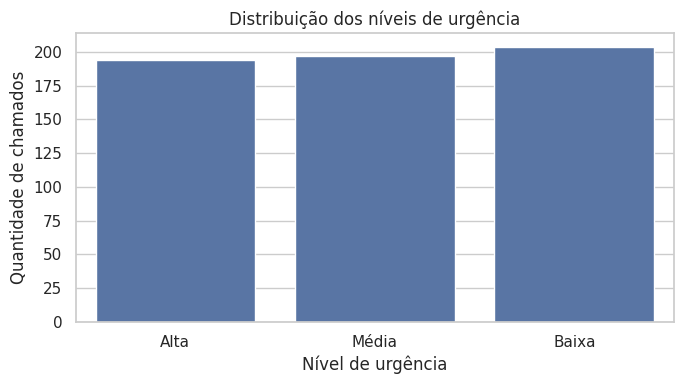

Observação: verifique se as classes estão representadas em quantidade suficiente.


In [23]:
# 4. Visualizar a distribuição das classes
plt.figure(figsize=(7, 4))
ordem = [c for c in ["Alta", "Média", "Baixa"] if c in df["urgencia"].unique()]
sns.countplot(data=df, x="urgencia", order=ordem)
plt.title("Distribuição dos níveis de urgência")
plt.xlabel("Nível de urgência")
plt.ylabel("Quantidade de chamados")
plt.tight_layout()
plt.show()

print("Observação: verifique se as classes estão representadas em quantidade suficiente.")

## 5. Separar treino e teste

O conjunto de teste fica separado até a avaliação final. A divisão estratificada procura preservar a proporção das classes em ambos os conjuntos. O TF-IDF será ajustado dentro de cada pipeline, usando apenas os dados de treino, para reduzir risco de vazamento de informação.

In [24]:
# Codificar os rótulos como números para compatibilidade entre modelos
le = LabelEncoder()
y = le.fit_transform(df["urgencia"])
X = df["mensagem"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Classes codificadas:", dict(zip(le.classes_, le.transform(le.classes_))))
print("Treino:", len(X_train), "| Teste:", len(X_test))
print("Distribuição no treino:", dict(zip(*np.unique(y_train, return_counts=True))))

Classes codificadas: {'Alta': np.int64(0), 'Baixa': np.int64(1), 'Média': np.int64(2)}
Treino: 476 | Teste: 119
Distribuição no treino: {np.int64(0): np.int64(155), np.int64(1): np.int64(163), np.int64(2): np.int64(158)}


## 6. Treinar e comparar modelos

O SVM com kernel linear costuma ser uma boa referência para classificação de texto com TF-IDF. O Random Forest fornece uma abordagem baseada em árvores. O XGBoost será incluído quando estiver disponível no ambiente.

In [25]:
# Pipeline 1: TF-IDF + SVM
modelo_svm = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True, strip_accents="unicode",
        ngram_range=(1, 2), max_features=5000, min_df=1
    )),
    ("clf", SVC(kernel="linear", probability=True, class_weight="balanced",
                random_state=RANDOM_STATE))
])

# Pipeline 2: TF-IDF + Random Forest
modelo_rf = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True, strip_accents="unicode",
        ngram_range=(1, 2), max_features=5000, min_df=1
    )),
    ("clf", RandomForestClassifier(
        n_estimators=250, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    ))
])

modelos = {"SVM": modelo_svm, "Random Forest": modelo_rf}

# Pipeline 3: XGBoost (opcional)
try:
    from xgboost import XGBClassifier
    modelo_xgb = Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True, strip_accents="unicode",
            ngram_range=(1, 2), max_features=5000, min_df=1
        )),
        ("clf", XGBClassifier(
            objective="multi:softprob", num_class=len(le.classes_),
            n_estimators=180, max_depth=5, learning_rate=0.08,
            subsample=0.9, colsample_bytree=0.9,
            eval_metric="mlogloss", random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
    modelos["XGBoost"] = modelo_xgb
except Exception as e:
    print("XGBoost não foi incluído:", e)

resultados = []
modelos_treinados = {}
predicoes = {}

for nome, modelo in modelos.items():
    print(f"Treinando {nome}...")
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    modelos_treinados[nome] = modelo
    predicoes[nome] = pred
    resultados.append({
        "Modelo": nome,
        "Accuracy": accuracy_score(y_test, pred),
        "F1 macro": f1_score(y_test, pred, average="macro"),
        "F1 ponderado": f1_score(y_test, pred, average="weighted")
    })

comparacao = pd.DataFrame(resultados).sort_values("F1 macro", ascending=False)
display(comparacao.round(4))

Treinando SVM...
Treinando Random Forest...
Treinando XGBoost...


,Modelo,Accuracy,F1 macro,F1 ponderado
0,SVM,1.0,1.0,1.0
1,Random Forest,1.0,1.0,1.0
2,XGBoost,1.0,1.0,1.0


Melhor modelo pelo F1 macro: SVM
              precision    recall  f1-score   support

        Alta       1.00      1.00      1.00        39
       Baixa       1.00      1.00      1.00        41
       Média       1.00      1.00      1.00        39

    accuracy                           1.00       119
   macro avg       1.00      1.00      1.00       119
weighted avg       1.00      1.00      1.00       119



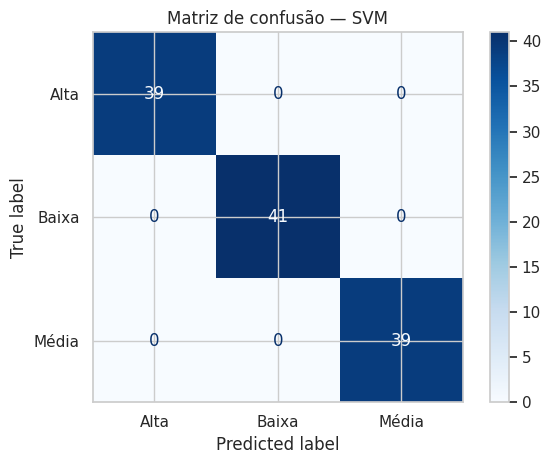

In [26]:
# 7. Relatório detalhado e matriz de confusão do melhor modelo
melhor_nome = comparacao.iloc[0]["Modelo"]
melhor_modelo = modelos_treinados[melhor_nome]
y_pred = predicoes[melhor_nome]

print("Melhor modelo pelo F1 macro:", melhor_nome)
print(classification_report(
    y_test, y_pred, labels=np.arange(len(le.classes_)),
    target_names=le.classes_, zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(le.classes_)))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Matriz de confusão — {melhor_nome}")
plt.tight_layout()
plt.show()

ROC-AUC macro OvR: 1.0000


<Figure size 700x500 with 0 Axes>

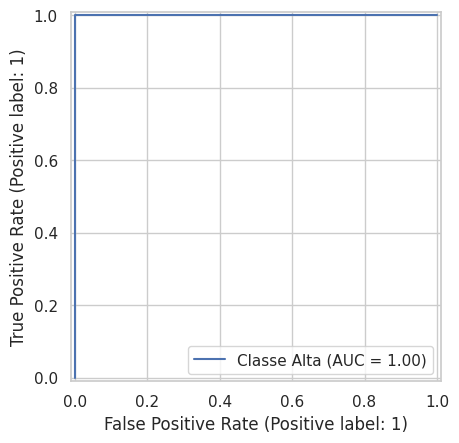

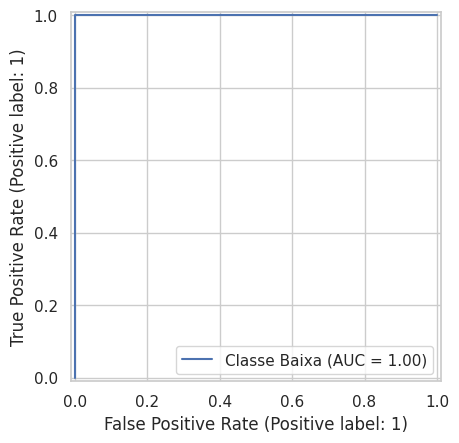

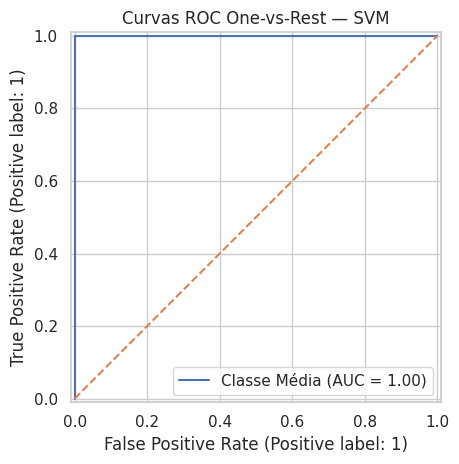

In [27]:
# 8. Curvas ROC/AUC multiclasse (estratégia One-vs-Rest)
try:
    y_score = melhor_modelo.predict_proba(X_test)
    y_test_bin = label_binarize(y_test, classes=np.arange(len(le.classes_)))
    auc_macro = roc_auc_score(y_test_bin, y_score, average="macro", multi_class="ovr")
    print(f"ROC-AUC macro OvR: {auc_macro:.4f}")

    plt.figure(figsize=(7, 5))
    for i, classe in enumerate(le.classes_):
        RocCurveDisplay.from_predictions(
            y_test_bin[:, i], y_score[:, i], name=f"Classe {classe}"
        )
    plt.plot([0, 1], [0, 1], linestyle="--", label="Referência aleatória")
    plt.title(f"Curvas ROC One-vs-Rest — {melhor_nome}")
    plt.tight_layout()
    plt.show()
except Exception as e:
    print("Não foi possível calcular a curva ROC/AUC:", e)
    print("Verifique se todas as classes aparecem no conjunto de teste.")

In [28]:
# 9. Validação cruzada estratificada (F1 macro)
# Usa o SVM como referência e executa a vetorização dentro de cada fold.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores_cv = cross_val_score(
    modelo_svm, X_train, y_train,
    scoring="f1_macro", cv=cv, n_jobs=-1
)
print("F1 macro por fold:", np.round(scores_cv, 4))
print(f"F1 macro médio: {scores_cv.mean():.4f} ± {scores_cv.std():.4f}")
print("A diferença entre desempenho de treino/validação e teste deve ser analisada; "
      "uma diferença grande pode indicar overfitting ou mudança na distribuição dos dados.")

F1 macro por fold: [1. 1. 1. 1. 1.]
F1 macro médio: 1.0000 ± 0.0000
A diferença entre desempenho de treino/validação e teste deve ser analisada; uma diferença grande pode indicar overfitting ou mudança na distribuição dos dados.


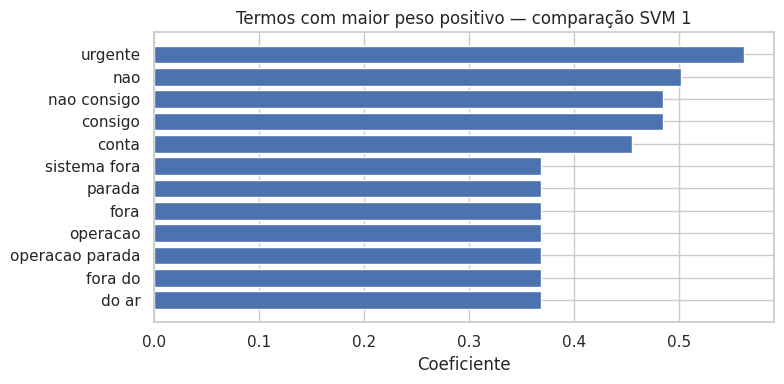

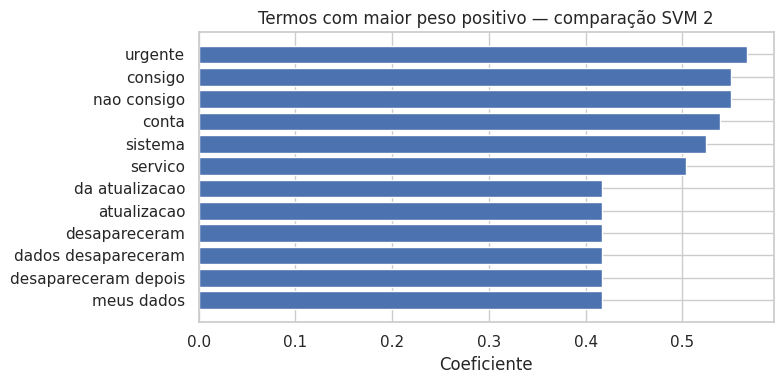

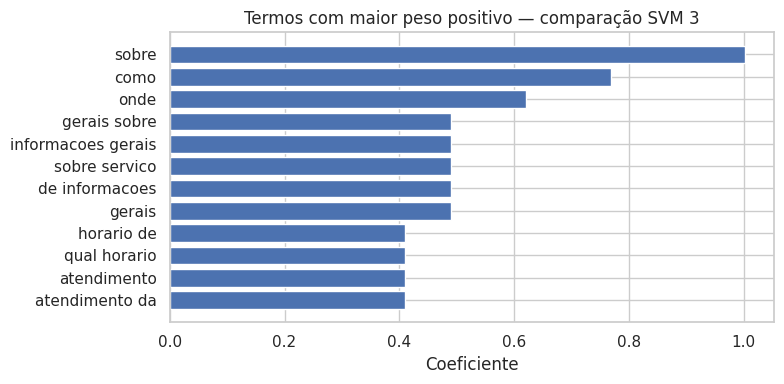

In [29]:
# 10. Importância de termos no SVM linear
# Para o SVM linear, os coeficientes indicam quais termos favorecem cada classe.
svm_final = modelos_treinados.get("SVM")
if svm_final is not None:
    vetor = svm_final.named_steps["tfidf"]
    clf = svm_final.named_steps["clf"]
    termos = np.array(vetor.get_feature_names_out())
    # Converter a matriz esparsa de coeficientes para um array denso do NumPy
    coefs = clf.coef_.toarray()

    # SVC multiclasse linear usa uma linha de coeficientes por comparação de classes.
    for idx, coef in enumerate(coefs):
        top_idx = np.argsort(coef)[-12:][::-1]
        plt.figure(figsize=(8, 4))
        plt.barh(termos[top_idx][::-1], coef[top_idx][::-1])
        plt.title(f"Termos com maior peso positivo — comparação SVM {idx+1}")
        plt.xlabel("Coeficiente")
        plt.tight_layout()
        plt.show()
else:
    print("SVM não está disponível para análise de coeficientes.")

## 11. Discussão crítica e aspectos éticos

- **Dados:** a base sintética foi criada para demonstrar o funcionamento técnico. Não representa a linguagem, a frequência nem a complexidade de chamados reais.
- **Métricas:** accuracy não deve ser usada sozinha; F1 macro ajuda a observar o desempenho das três classes. Revise a matriz de confusão para identificar erros por classe.
- **Validação:** a validação cruzada é aplicada no conjunto de treino; o teste é reservado para avaliação final.
- **Viés:** mensagens curtas, erros de digitação, regionalismos e linguagem ofensiva podem alterar as previsões. O modelo não deve punir clientes pela forma de escrever.
- **Uso responsável:** a urgência prevista deve apoiar a triagem, não substituir totalmente a avaliação humana. Chamados de alto impacto devem permitir revisão e escalonamento.
- **Produção:** antes de implantar, é necessário validar com dados reais rotulados, monitorar métricas por classe, proteger dados pessoais conforme a LGPD e reavaliar o modelo periodicamente.

### Limitações desta demonstração
Resultados elevados em dados sintéticos podem refletir padrões artificiais e não indicam desempenho real. Para avaliar o objetivo de negócio de reduzir o tempo médio de atendimento em 40%, seria necessário um piloto com dados reais e uma comparação antes/depois. A meta de 40% é uma meta proposta no enunciado, não um resultado comprovado por este notebook.

In [30]:
# 12. Exemplo de previsão para uma nova mensagem
mensagem_nova = ["O sistema está fora do ar e não consigo acessar minha conta."]
classe_prevista = melhor_modelo.predict(mensagem_nova)[0]
print("Mensagem:", mensagem_nova[0])
print("Urgência prevista:", le.inverse_transform([classe_prevista])[0])
print("Nota: previsão demonstrativa; decisões reais devem considerar validação humana.")

Mensagem: O sistema está fora do ar e não consigo acessar minha conta.
Urgência prevista: Alta
Nota: previsão demonstrativa; decisões reais devem considerar validação humana.


Preparando os dados para a rede neural...
Epoch 1/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 55ms/step - accuracy: 0.5079 - loss: 1.0613 - val_accuracy: 0.9062 - val_loss: 1.0122
Epoch 2/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.8500 - loss: 0.9632 - val_accuracy: 0.9792 - val_loss: 0.9040
Epoch 3/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9421 - loss: 0.8283 - val_accuracy: 1.0000 - val_loss: 0.7311
Epoch 4/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9921 - loss: 0.6354 - val_accuracy: 1.0000 - val_loss: 0.4957
Epoch 5/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9921 - loss: 0.4051 - val_accuracy: 1.0000 - val_loss: 0.2614
Epoch 6/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 1.0000 - loss: 0.2062 - val_accuracy: 1.0000 - val_loss: 0.1080
Epoch 7/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 1.0000 - loss: 0.0919 - val_accuracy: 1.0000 - val_loss: 0.0436
Epoch 8/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 1.0000

<Figure size 600x500 with 0 Axes>

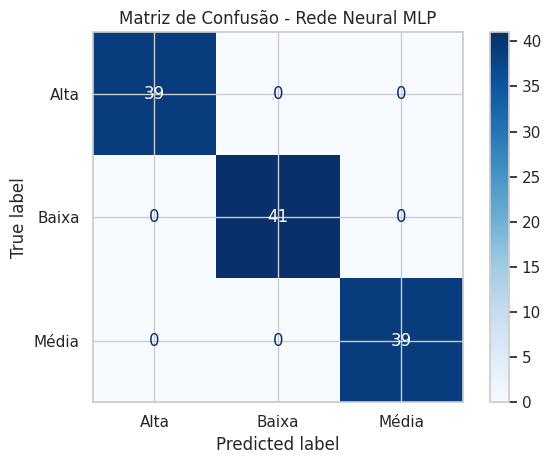

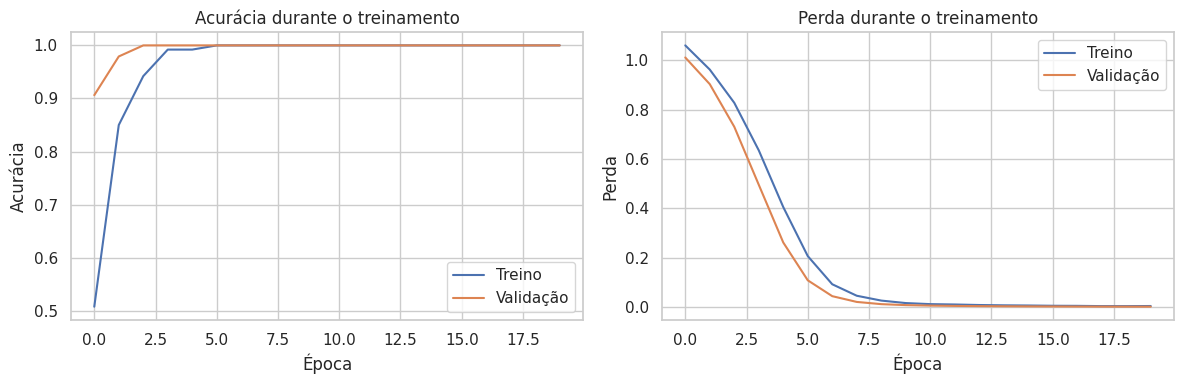


Treinamento da rede neural concluído!


In [31]:
# 13. Rede Neural MLP com Keras
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Definir sementes para reprodutibilidade
np.random.seed(42)
tf.random.set_seed(42)

print("Preparando os dados para a rede neural...")

# Vetorização TF-IDF para o MLP
vectorizer_mlp = TfidfVectorizer(max_features=5000)
X_train_mlp = vectorizer_mlp.fit_transform(X_train.astype(str)).toarray()
X_test_mlp = vectorizer_mlp.transform(X_test.astype(str)).toarray()

# Como y_train e y_test já estão codificados numericamente pelo primeiro LabelEncoder (le),
# usaremos diretamente as classes originais em formato string para evitar dupla codificação.
nome_classes = [str(c) for c in le.classes_]
num_classes = len(nome_classes)

# Ajustar dados de treino para garantir correspondência das dimensões
y_train_mlp = np.asarray(y_train)
y_test_mlp = np.asarray(y_test)

# Construção do modelo MLP
model_mlp = Sequential([
    Dense(128, activation='relu', input_shape=(X_train_mlp.shape[1],)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(num_classes, activation='softmax')
])

# Compilação do modelo
model_mlp.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Parada antecipada (Early Stopping)
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Treinamento
history = model_mlp.fit(
    X_train_mlp, y_train_mlp,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

# Avaliação no conjunto de testes
loss, accuracy = model_mlp.evaluate(X_test_mlp, y_test_mlp, verbose=0)
print(f"\nAcurácia da Rede Neural MLP: {accuracy:.4f}")
print(f"Perda no teste: {loss:.4f}")

# Predições
y_pred = np.argmax(model_mlp.predict(X_test_mlp, verbose=0), axis=1)

# Relatório de Classificação
print("\nRelatório de Classificação - MLP:")
print(classification_report(
    y_test_mlp, y_pred,
    labels=np.arange(num_classes),
    target_names=nome_classes,
    zero_division=0
))

# Matriz de Confusão
cm_mlp = confusion_matrix(y_test_mlp, y_pred, labels=np.arange(num_classes))
plt.figure(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=cm_mlp,
    display_labels=nome_classes
).plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusão - Rede Neural MLP")
plt.tight_layout()
plt.show()

# Histórico de Treinamento
plt.figure(figsize=(12, 4))

# Plot de Acurácia
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Treino')
plt.plot(history.history['val_accuracy'], label='Validação')
plt.title('Acurácia durante o treinamento')
plt.xlabel('Época')
plt.ylabel('Acurácia')
plt.legend()

# Plot de Perda
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Treino')
plt.plot(history.history['val_loss'], label='Validação')
plt.title('Perda durante o treinamento')
plt.xlabel('Época')
plt.ylabel('Perda')
plt.legend()

plt.tight_layout()
plt.show()

print("\nTreinamento da rede neural concluído!")